## **Delivery Duration Prediction**

### *An end-to-end regression project: predicting how long a food delivery will take*

## 1. Business Understanding

### 1.1 Business Overview

DoorDash is an online food delivery marketplace that connects customers, restaurants and delivery drivers (called dashers). When a customer places an order, the app shows the expected time of delivery.

This estimate strongly affects customer experience. If the estimate is too short, customers receive their food late and lose trust. If it is too long, customers may choose another platform. Getting the delivery time right is therefore important for customer satisfaction and retention.

### 1.2 Problem Statement

The delivery time depends on many things such as how busy the restaurant is, how many dashers are available, the size of the order and the time of day. Some of these factors are not directly observed, which makes accurate estimation difficult.

This project builds a regression model that predicts the total delivery duration in seconds, from the moment the customer submits the order (`created_at`) to the moment it is delivered (`actual_delivery_time`).

### 1.3 Business Objectives

#### 1.3.1 Main Objective

Develop a regression model that accurately predicts the total delivery duration of an order, so the company can show customers more reliable delivery estimates.

#### 1.3.2 Specific Objectives

1. Clean the data and create useful features from the order, store, time and marketplace information.
2. Build and compare several regression models, including a stacked ensemble.
3. Evaluate the models on future orders that were not used for training.
4. Identify the features that have the greatest influence on delivery time.

#### 1.3.3 Research Questions

1. How accurately can delivery duration be predicted compared to simple baselines?
2. Which features have the greatest influence on delivery duration?
3. Does splitting the problem into known stages (order placement and driving) and an unknown remainder (restaurant preparation) improve predictions?
4. Does a stacked ensemble improve over the best single model?

### 1.4 Success Criteria

- **Technical success:** the final model should clearly beat the baselines (predicting the average duration, and a linear model on the provided time estimates) on the main metric, RMSE. MAE, R² and the percentage of orders predicted within 10 minutes are used as supporting metrics.
- **Business success:** the analysis should explain which factors drive delivery time and give recommendations on how the estimate can be improved.

## 2. Data Understanding

This section introduces the dataset used in the project. It contains a subset of DoorDash deliveries from early 2015. Each row is one unique delivery. Money values are in cents and time durations are in seconds. Noise was added to the data by the dataset authors to hide certain business details.

### 2.1 Loading and Previewing the Dataset

In [77]:
%pip install lightgbm

#### 2.1.1 Importing Required Libraries

In [78]:
# Data loading and manipulation
import pandas as pd
import numpy as np

# Data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Modeling and evaluation
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from lightgbm import LGBMRegressor

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Set plot style
sns.set_style('whitegrid')

The helper functions used in this notebook are stored in `utility.py`.

In [79]:
# Custom function loading
import importlib
import utility

# Reloads the module to reflect changes
importlib.reload(utility)

<module 'utility' from 'c:\\Users\\PC\\OneDrive\\Documents\\DoorDash-Delivery-Duration-\\utility.py'>

#### 2.1.2 Loading the Dataset

In [80]:
# Load the dataset
df = pd.read_csv('historical_data.csv', parse_dates=['created_at', 'actual_delivery_time'])

#### 2.1.3 Previewing the Data

In [81]:
# Preview the first five rows
df.head()

,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,1845,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0,446,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,5477,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,446,690.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,5477,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0,446,690.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,5477,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0,446,289.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,5477,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0,446,650.0


- Each row is one delivery. The first rows show the order details, the marketplace state at order time and the two provided time estimates.
- Some values are already missing (for example `store_primary_category` and the dasher columns).

### 2.2 Data Overview

In [82]:
# Check the shape of the dataset
df.shape

(197428, 16)

- The dataset has 197,428 rows and 16 columns (17 once the target is added).

In [83]:
# Display data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197428 entries, 0 to 197427
Data columns (total 16 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   market_id                                     196441 non-null  float64       
 1   created_at                                    197428 non-null  datetime64[ns]
 2   actual_delivery_time                          197421 non-null  datetime64[ns]
 3   store_id                                      197428 non-null  int64         
 4   store_primary_category                        192668 non-null  object        
 5   order_protocol                                196433 non-null  float64       
 6   total_items                                   197428 non-null  int64         
 7   subtotal                                      197428 non-null  int64         
 8   num_distinct_items                            197428 n

- The two time columns were parsed as datetimes, so the target can be calculated directly.
- `store_primary_category` is text. Several columns have missing values, for example the dasher columns (181,166 non-null) and `actual_delivery_time` (197,421 non-null).

Below is a description of the features in the dataset:

**Time features**
- `market_id`: the city or region where the order was placed.
- `created_at`: time the customer submitted the order (UTC).
- `actual_delivery_time`: time the order was delivered (UTC).

**Store features**
- `store_id`: the restaurant the order was placed with.
- `store_primary_category`: the cuisine category of the restaurant.
- `order_protocol`: the way the restaurant receives orders from DoorDash.

**Order features**
- `total_items`, `num_distinct_items`: number of items and number of different items in the order.
- `subtotal`, `min_item_price`, `max_item_price`: order value and the lowest and highest item prices (in cents).

**Market features** (measured when the order is created)
- `total_onshift_dashers`: available dashers within 10 miles of the store.
- `total_busy_dashers`: dashers among those who are already working on an order.
- `total_outstanding_orders`: orders within 10 miles that are being processed.

**Predictions from other models**
- `estimated_order_place_duration`: estimated time for the restaurant to receive the order.
- `estimated_store_to_consumer_driving_duration`: estimated driving time from store to customer.

#### 2.2.1 Creating the Target Variable

The target is the total number of seconds between `created_at` and `actual_delivery_time`.

In [84]:
# Create the target variable in seconds
df['delivery_duration'] = (df['actual_delivery_time'] - df['created_at']).dt.total_seconds()

### 2.3 Descriptive Statistics

In [85]:
# Display summary statistics
df.describe().T

,count,mean,min,25%,50%,75%,max,std
market_id,196441.0,2.978706,1.0,2.0,3.0,4.0,6.0,1.524867
created_at,197428,2015-02-04 22:00:09.537962752,2014-10-19 05:24:15,2015-01-29 02:32:42,2015-02-05 03:29:09.500000,2015-02-12 01:39:18.500000,2015-02-18 06:00:44,NaN
actual_delivery_time,197421,2015-02-04 22:48:23.348914432,2015-01-21 15:58:11,2015-01-29 03:22:29,2015-02-05 04:40:41,2015-02-12 02:25:26,2015-02-19 22:45:31,NaN
store_id,197428.0,3530.510272,1.0,1686.0,3592.0,5299.0,6987.0,2053.496711
order_protocol,196433.0,2.882352,1.0,1.0,3.0,4.0,7.0,1.503771
total_items,197428.0,3.196391,1.0,2.0,3.0,4.0,411.0,2.666546
subtotal,197428.0,2682.331402,0.0,1400.0,2200.0,3395.0,27100.0,1823.093688
num_distinct_items,197428.0,2.670791,1.0,1.0,2.0,3.0,20.0,1.630255
min_item_price,197428.0,686.21847,-86.0,299.0,595.0,949.0,14700.0,522.038648
max_item_price,197428.0,1159.58863,0.0,800.0,1095.0,1395.0,14700.0,558.411377


- The average delivery takes about 2,900 seconds (48 minutes), but the maximum is about 8.5 million seconds (around 98 days). This is clearly a data error and shows the target has extreme outliers.
- The shortest delivery is 101 seconds.
- Some marketplace columns contain negative values, which are not possible for counts of dashers or orders.

In [86]:
# Check for missing values
df.isnull().sum()

market_id                                         987
created_at                                          0
actual_delivery_time                                7
store_id                                            0
store_primary_category                           4760
order_protocol                                    995
total_items                                         0
subtotal                                            0
num_distinct_items                                  0
min_item_price                                      0
max_item_price                                      0
total_onshift_dashers                           16262
total_busy_dashers                              16262
total_outstanding_orders                        16262
estimated_order_place_duration                      0
estimated_store_to_consumer_driving_duration      526
delivery_duration                                   7
dtype: int64

- `total_onshift_dashers`, `total_busy_dashers` and `total_outstanding_orders` each have 16,262 missing values.
- `store_primary_category` has 4,760 missing values, `order_protocol` 995, `market_id` 987 and the driving estimate 526.
- 7 rows have no delivery time, so their target cannot be calculated.

In [87]:
# Check for duplicate rows
df.duplicated().sum()

0

- There are no duplicate rows.

In [88]:
# Check the orders per month
df['created_at'].dt.to_period('M').value_counts().sort_index()

created_at
2014-10         1
2015-01     68482
2015-02    128945
Freq: M, Name: count, dtype: int64

- Almost all orders are from January (68,482) and February 2015 (128,945), plus a single order from October 2014.
- The data covers only about five weeks. This is a short history, so seasonal effects cannot be learned and store history will be limited.

### 2.4 Key Observations

Based on the initial review of the dataset, the following observations were made:

- The dataset has 197,428 deliveries and 16 columns, covering about five weeks (January to February 2015).
- The target (delivery duration) has a few impossible values, including one of about 98 days. These need to be removed.
- Missing values are present in the store category, market, order protocol, driving estimate and in the three dasher columns. The dasher columns are missing mostly in one market.
- There are negative values in columns that cannot be negative, and about 20% of rows where busy dashers exceed on-shift dashers. These are signs of noise added to the data.
- There are no duplicate rows.

## 3. Data Preparation

In this section we clean the data, explore it, create new features, split it into training and test sets and prepare it for modeling.

### 3.1 Data Cleaning

The cleaning steps are:

- Remove rows with no delivery time (the target cannot be calculated).
- Remove deliveries that took more than 3 hours. These are extreme outliers caused by data errors.
- Replace impossible negative values with missing values.
- Sort the data by order time, which is needed for a time-based split later.

#### 3.1.1 Handling Missing Target Values

In [89]:
# Drop rows with no delivery time
df_clean = df.dropna(subset=['delivery_duration']).copy()
print(f'Rows removed: {len(df) - len(df_clean)}')

Rows removed: 7


- 7 rows without a delivery time were removed.

#### 3.1.2 Handling Target Outliers

In [90]:
# Look at the largest delivery durations (in hours)
(df_clean['delivery_duration'].sort_values(ascending=False).head(10) / 3600).round(1)

2690      2365.8
185550     103.9
27189       92.4
83055       15.8
190860      15.1
86952       13.4
76743       12.7
105825      10.9
66787       10.7
175971      10.6
Name: delivery_duration, dtype: float64

- The longest delivery is about 2,366 hours (98 days), followed by deliveries of 104 and 92 hours. The rest of the top ten are between 10 and 16 hours.
- A normal delivery takes about two hours, so a cut-off of 3 hours keeps all realistic deliveries and removes the data errors.

In [91]:
# Remove deliveries longer than 3 hours
before = len(df_clean)
df_clean = df_clean[df_clean['delivery_duration'] <= 3 * 3600].copy()
print(f'Rows removed: {before - len(df_clean)}')
print(f'Rows remaining: {len(df_clean)}')

Rows removed: 138
Rows remaining: 197283


- 138 rows (about 0.07% of the data) were removed. 197,283 rows remain.

#### 3.1.3 Handling Negative Values

In [92]:
# Count negative values in columns that cannot be negative
neg_cols = ['total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'min_item_price']
(df_clean[neg_cols] < 0).sum()

total_onshift_dashers       21
total_busy_dashers          21
total_outstanding_orders    44
min_item_price              13
dtype: int64

- Negative values are rare: 21 in each of the on-shift and busy dasher columns, 44 in outstanding orders and 13 in the minimum item price.
- They were changed to missing values, which the models can handle.

In [93]:
# Replace the negative values with missing values
for col in neg_cols:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

#### 3.1.4 Sorting by Time

In [94]:
# Sort by order time and reset the index
df_clean = df_clean.sort_values('created_at').reset_index(drop=True)
df_clean[['created_at', 'delivery_duration']].head()

,created_at,delivery_duration
0,2015-01-21 15:22:03,3340.0
1,2015-01-21 15:31:51,2683.0
2,2015-01-21 15:39:16,1135.0
3,2015-01-21 15:40:42,2515.0
4,2015-01-21 15:41:33,3221.0


### 3.2 Exploratory Data Analysis

This section explores the cleaned data to understand the distribution of the target, the missing values and the relationships between features and delivery duration.

#### 3.2.1 Univariate Analysis

##### 3.2.1.1 Delivery Duration Distribution

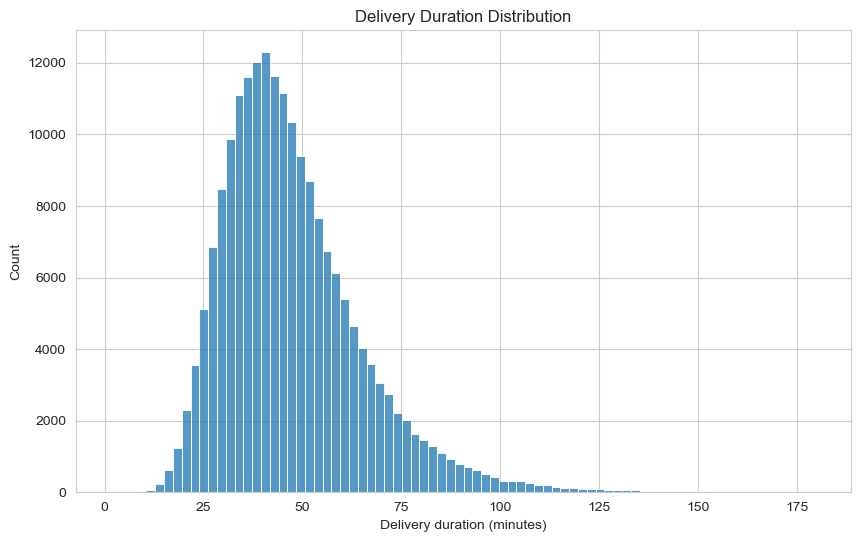

In [95]:
# Distribution of the target in minutes
plt.figure(figsize=(10, 6))
sns.histplot(df_clean['delivery_duration'] / 60, bins=80)
plt.title('Delivery Duration Distribution')
plt.xlabel('Delivery duration (minutes)')
plt.ylabel('Count')
plt.show()

- The distribution is right-skewed. Most deliveries take between 30 and 60 minutes and there is a long tail of slow deliveries.

In [96]:
# Summary statistics of the target in minutes
(df_clean['delivery_duration'] / 60).describe()

count    197283.000000
mean         47.533562
std          18.041246
min           1.683333
25%          35.066667
50%          44.316667
75%          56.316667
max         179.850000
Name: delivery_duration, dtype: float64

- The median delivery takes 44.3 minutes and the average is 47.5 minutes. Half of the deliveries fall between 35 and 56 minutes.

##### 3.2.1.2 Market and Order Protocol Distribution

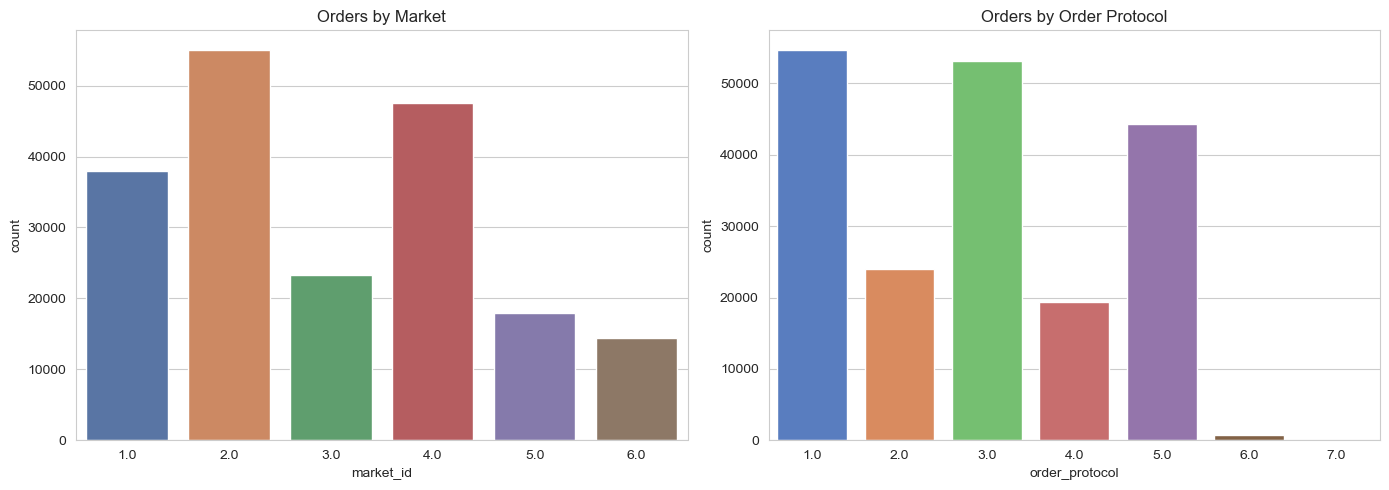

In [97]:
# Count of orders by market and order protocol
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='market_id', data=df_clean, ax=axes[0], palette='deep')
axes[0].set_title('Orders by Market')

sns.countplot(x='order_protocol', data=df_clean, ax=axes[1], palette='muted')
axes[1].set_title('Orders by Order Protocol')

plt.tight_layout()
plt.show()

- Market 2 has the most orders (about 55,000), followed by markets 4 and 1. Market 6 has the fewest (about 14,000).
- Order protocols 1, 3 and 5 account for most orders. Protocols 6 and 7 are rare (790 and 19 orders).

##### 3.2.1.3 Store Primary Category

In [98]:
# Ten most common cuisine categories
df_clean['store_primary_category'].value_counts().head(10)

store_primary_category
american    19385
pizza       17308
mexican     17088
burger      10952
sandwich    10052
chinese      9415
japanese     9188
dessert      8763
fast         7365
indian       7309
Name: count, dtype: int64

- American, pizza and Mexican are the most common cuisines.

##### 3.2.1.5 Data Quality Check on Dasher Columns

In [99]:
# Rows where busy dashers are more than on-shift dashers (not logically possible)
busy_gt = (df_clean['total_busy_dashers'] > df_clean['total_onshift_dashers']).sum()
print(f'Rows with busy > onshift: {busy_gt} ({busy_gt / len(df_clean) * 100:.1f}%)')

Rows with busy > onshift: 40348 (20.5%)


- In 40,348 rows (20.5%) there are more busy dashers than on-shift dashers, which is not logically possible. This is probably part of the noise added to the data.
- Because it affects so many rows, they are kept and a `busy_gt_onshift` flag is added as a feature.

#### 3.2.2 Bivariate Analysis

##### 3.2.2.1 Market vs Delivery Duration

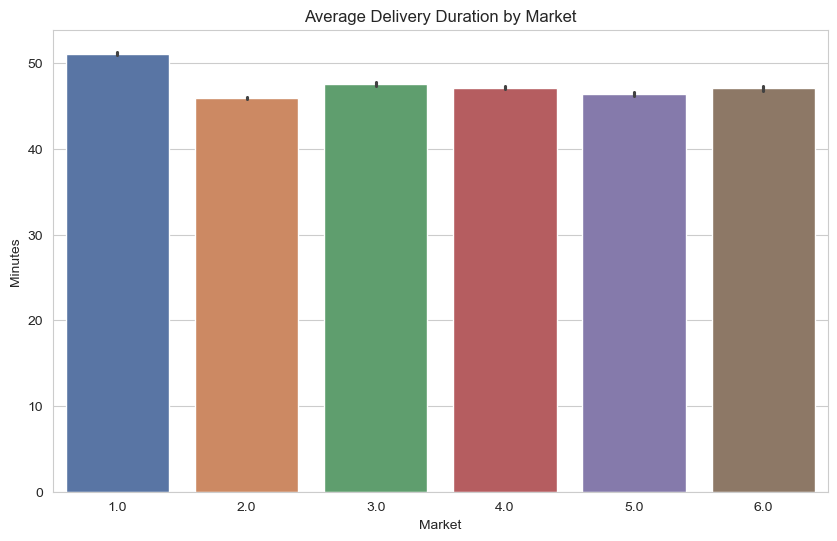

In [100]:
# Average delivery duration by market
plt.figure(figsize=(10, 6))
sns.barplot(x='market_id', y=df_clean['delivery_duration'] / 60, data=df_clean, palette='deep')
plt.title('Average Delivery Duration by Market')
plt.xlabel('Market')
plt.ylabel('Minutes')
plt.show()

- Market 1 has the longest deliveries (about 51 minutes). The other markets are between 46 and 47.5 minutes.
- The market is therefore a useful feature.

##### 3.2.2.2 Order Protocol vs Delivery Duration

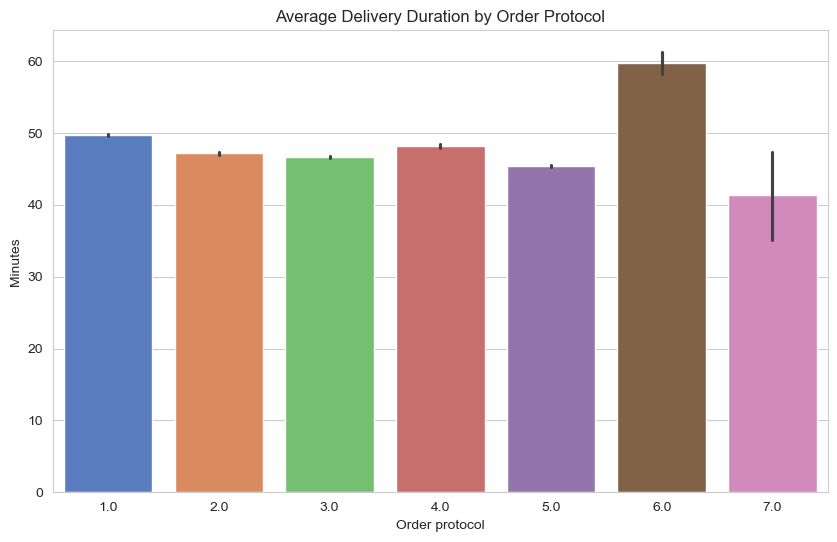

In [101]:
# Average delivery duration by order protocol
plt.figure(figsize=(10, 6))
sns.barplot(x='order_protocol', y=df_clean['delivery_duration'] / 60, data=df_clean, palette='muted')
plt.title('Average Delivery Duration by Order Protocol')
plt.xlabel('Order protocol')
plt.ylabel('Minutes')
plt.show()

- Order protocol 6 has the longest average (about 60 minutes) but only 790 orders. Protocol 1 averages about 50 minutes and the others between 45 and 48 minutes.
- Protocol 7 (41 minutes) has only 19 orders and should not be over-interpreted.

##### 3.2.2.3 Provided Estimates vs Delivery Duration

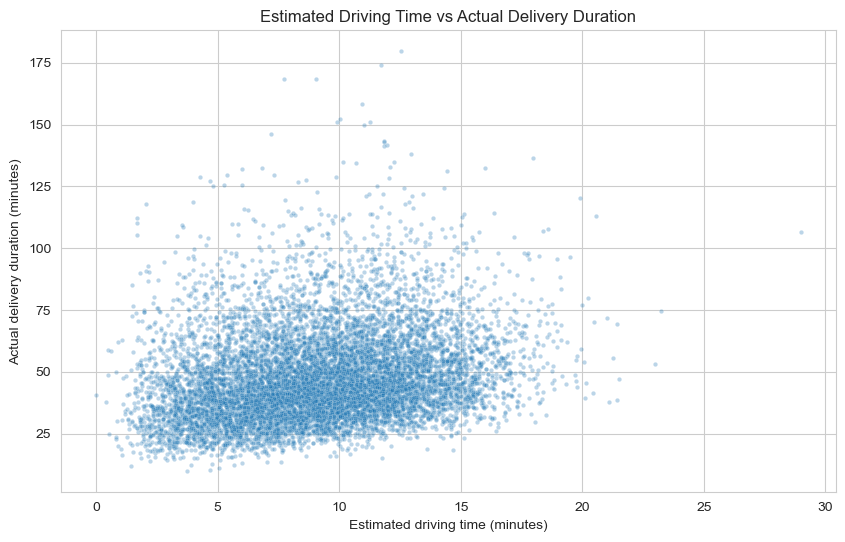

In [102]:
# Estimated driving time vs actual delivery duration (sample of orders)
sample = df_clean.sample(10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=sample['estimated_store_to_consumer_driving_duration'] / 60,
                y=sample['delivery_duration'] / 60, alpha=0.3, s=10)
plt.title('Estimated Driving Time vs Actual Delivery Duration')
plt.xlabel('Estimated driving time (minutes)')
plt.ylabel('Actual delivery duration (minutes)')
plt.show()

- There is a positive relationship, but with a very wide spread. A delivery with a short estimated drive can still take more than an hour.
- This shows that driving is only a small part of the total time. Restaurant preparation and waiting time matter more.

##### 3.2.2.4 Marketplace Load vs Delivery Duration

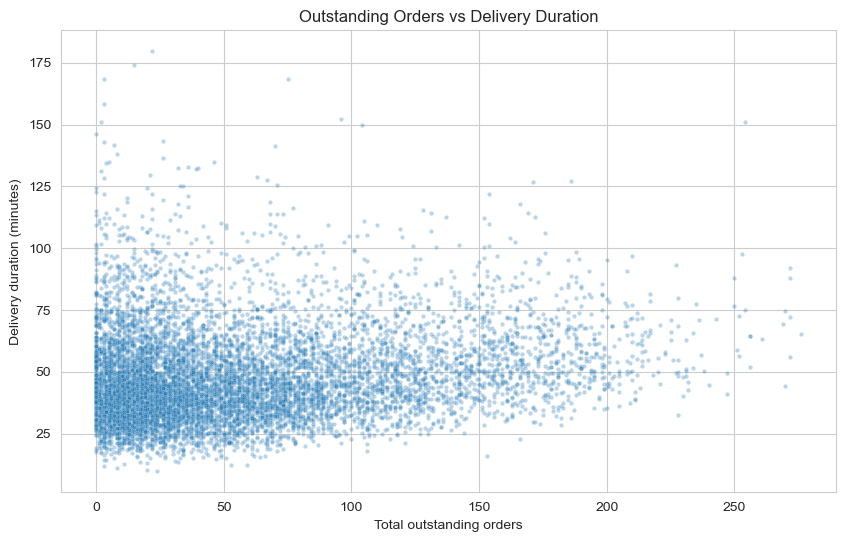

In [103]:
# Delivery duration vs number of outstanding orders
plt.figure(figsize=(10, 6))
sns.scatterplot(x=sample['total_outstanding_orders'], y=sample['delivery_duration'] / 60, alpha=0.3, s=10)
plt.title('Outstanding Orders vs Delivery Duration')
plt.xlabel('Total outstanding orders')
plt.ylabel('Delivery duration (minutes)')
plt.show()

- Delivery duration tends to rise with the number of outstanding orders, but the relationship is noisy (correlation about 0.19).

#### 3.2.3 Feature Correlation

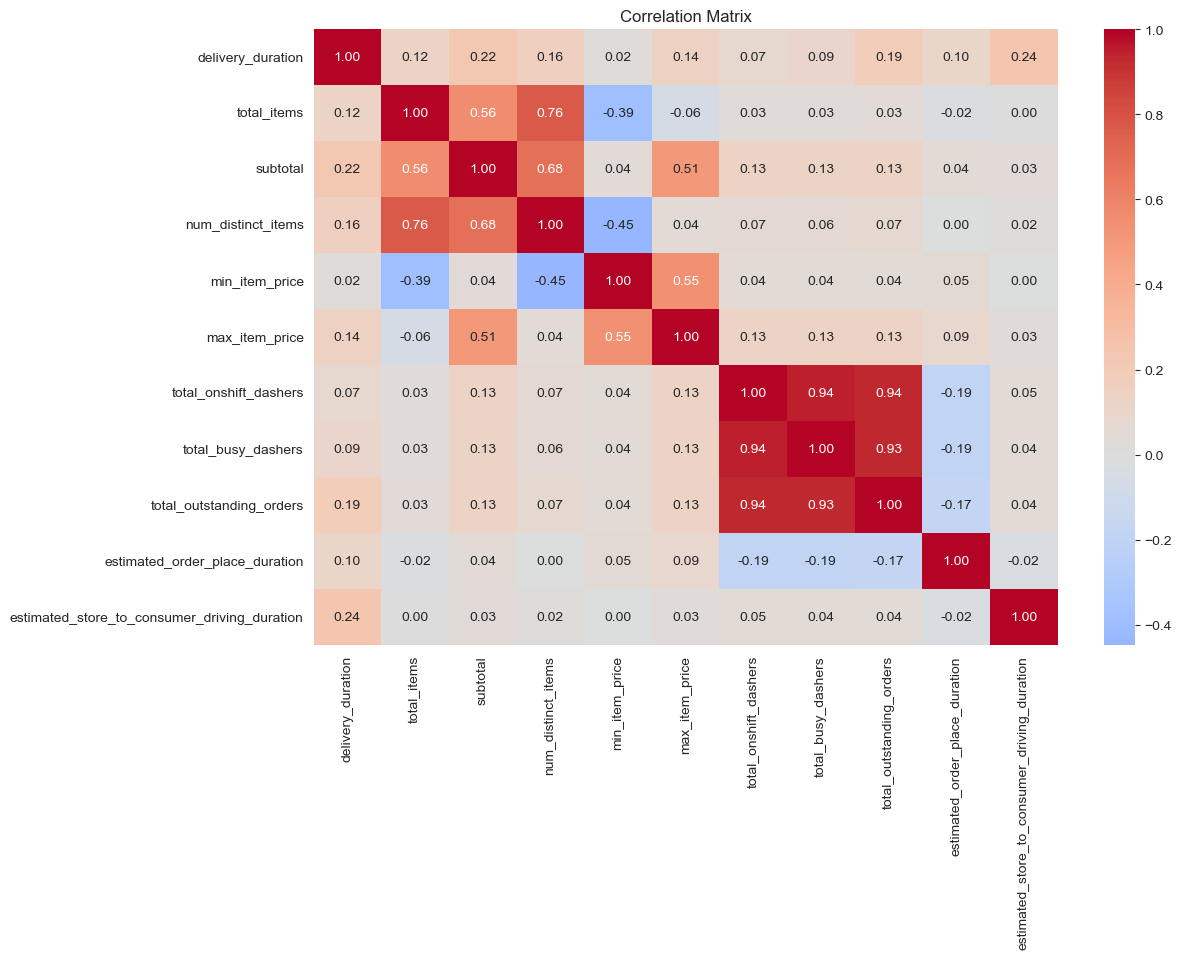

In [104]:
# Correlation matrix of the numeric columns
numeric_cols = ['delivery_duration', 'total_items', 'subtotal', 'num_distinct_items',
                'min_item_price', 'max_item_price', 'total_onshift_dashers',
                'total_busy_dashers', 'total_outstanding_orders',
                'estimated_order_place_duration', 'estimated_store_to_consumer_driving_duration']

plt.figure(figsize=(12, 8))
sns.heatmap(df_clean[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

- No single feature is strongly correlated with the target. The highest are the driving estimate (0.24), subtotal (0.22) and outstanding orders (0.19).
- The three dasher columns are very highly correlated with each other (0.93 to 0.94), so ratios between them are more informative than the raw counts.
- `total_items`, `num_distinct_items` and `subtotal` are also correlated with each other.
- The weak linear correlations suggest that non-linear models and engineered features are needed.

### 3.3 Feature Engineering

New features are created from the existing columns. They are grouped into time, marketplace and order features. The functions are in `utility.py`.

#### 3.3.1 Time Features

The orders are converted from UTC to the local US/Pacific time, so the hour of the day matches real meal times.

In [105]:
# Create time features
df_fe = utility.add_time_features(df_clean)
df_fe[['created_at', 'hour', 'hour_frac', 'day_of_week', 'is_weekend']].head()

,created_at,hour,hour_frac,day_of_week,is_weekend
0,2015-01-21 15:22:03,7,7.366667,2,0
1,2015-01-21 15:31:51,7,7.516667,2,0
2,2015-01-21 15:39:16,7,7.650000,2,0
3,2015-01-21 15:40:42,7,7.666667,2,0
4,2015-01-21 15:41:33,7,7.683333,2,0


- The conversion to local time works as expected. For example, 15:22 UTC is 7:22 AM in US/Pacific.

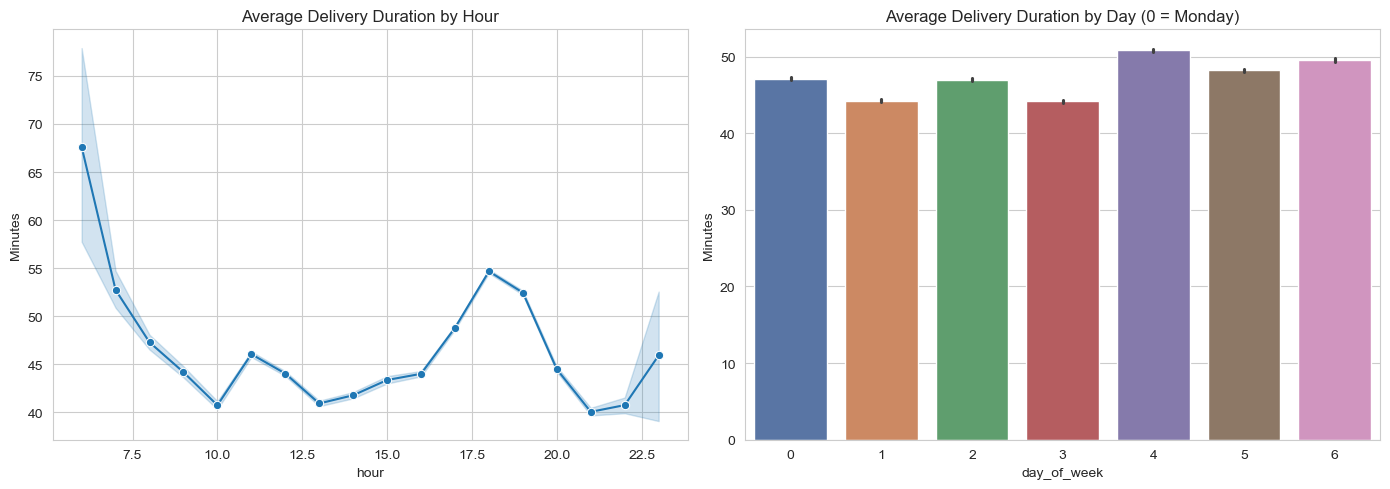

In [106]:
# Average delivery duration by hour and by day of the week
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(x='hour', y=df_fe['delivery_duration'] / 60, data=df_fe, marker='o', ax=axes[0])
axes[0].set_title('Average Delivery Duration by Hour')
axes[0].set_ylabel('Minutes')

sns.barplot(x='day_of_week', y=df_fe['delivery_duration'] / 60, data=df_fe, ax=axes[1], palette='deep')
axes[1].set_title('Average Delivery Duration by Day (0 = Monday)')
axes[1].set_ylabel('Minutes')

plt.tight_layout()
plt.show()

- Deliveries are slowest in the early morning (6 to 7 AM, with few orders) and at dinner time (6 to 7 PM, about 53 to 55 minutes). They are fastest late in the evening (9 to 10 PM, about 40 minutes).
- Friday is the slowest day (about 51 minutes) while Tuesday and Thursday are the fastest (about 44 minutes).
- Time of day and day of week are clearly useful features.

#### 3.3.2 Marketplace Features

In [107]:
# Create marketplace features
df_fe = utility.add_marketplace_features(df_fe)
df_fe[['free_dashers', 'busy_ratio', 'orders_per_onshift', 'orders_per_free',
       'dashers_missing', 'busy_gt_onshift']].describe().T

,count,mean,std,min,25%,50%,75%,max
free_dashers,180994.0,3.069223,11.423253,-64.0,0.000000,1.000000,6.000000,86.0
busy_ratio,177393.0,0.950432,0.401581,0.0,0.826923,0.962264,1.000000,31.0
orders_per_onshift,177369.0,1.219109,0.469311,0.0,0.941176,1.200000,1.478261,47.0
orders_per_free,104757.0,19.312051,29.131138,0.0,3.250000,8.000000,22.454545,262.0
dashers_missing,197283.0,0.082465,0.275073,0.0,0.000000,0.000000,0.000000,1.0
busy_gt_onshift,197283.0,0.204518,0.403350,0.0,0.000000,0.000000,0.000000,1.0


- `free_dashers` ranges from -64 to 86. The negative values come from rows where busy dashers exceed on-shift dashers.
- On average there are 1.2 outstanding orders per on-shift dasher.

#### 3.3.3 Order Features

In [108]:
# Create order features
df_fe = utility.add_order_features(df_fe)
df_fe[['avg_item_price', 'price_range', 'items_per_distinct']].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_item_price,197283.0,975.281695,517.010948,0.0,647.666667,895.0,1195.0,14700.0
price_range,197270.0,473.369549,516.078104,-198.0,0.000000,370.0,750.0,8400.0
items_per_distinct,197283.0,1.196529,0.569705,1.0,1.000000,1.0,1.2,82.2


- The median average item price is 895 cents ($8.95).
- `price_range` has a few negative values because in about 800 rows the minimum item price is above the maximum, another sign of noise in the data.

In [109]:
# Correlation of the new features with the target
new_features = ['hour_frac', 'is_weekend', 'free_dashers', 'busy_ratio', 'orders_per_onshift',
                'orders_per_free', 'avg_item_price', 'price_range', 'items_per_distinct']
df_fe[new_features + ['delivery_duration']].corr()['delivery_duration'].drop('delivery_duration').sort_values()

free_dashers         -0.042634
items_per_distinct    0.007585
is_weekend            0.051117
busy_ratio            0.063952
avg_item_price        0.079930
hour_frac             0.118396
price_range           0.131197
orders_per_free       0.236141
orders_per_onshift    0.345557
Name: delivery_duration, dtype: float64

- `orders_per_onshift` has the highest correlation with delivery duration of all the features so far (0.35), higher than any original column.
- `orders_per_free` (0.24), `price_range` (0.13) and `hour_frac` (0.12) also add information. The feature engineering is useful.

### 3.4 Train and Test Split

Because the model will be used to predict **future** orders, the data is split by time instead of randomly. The first 80% of orders (the earliest) are used for training and the last 20% for testing. A random split would let the model learn from orders placed at the same time as the test orders, which would give overly optimistic results.

In [110]:
# Time-based split
split_index = int(len(df_fe) * 0.8)

train_df = df_fe.iloc[:split_index].copy()
test_df = df_fe.iloc[split_index:].copy()

print(f'Train: {train_df.shape}, {train_df["created_at"].min()} to {train_df["created_at"].max()}')
print(f'Test: {test_df.shape}, {test_df["created_at"].min()} to {test_df["created_at"].max()}')

Train: (157826, 30), 2015-01-21 15:22:03 to 2015-02-13 04:06:37
Test: (39457, 30), 2015-02-13 04:06:44 to 2015-02-18 06:00:44


- The training set has 157,826 orders from January 21 to February 13 and the test set has 39,457 orders from February 13 to February 18.
- The test set only contains orders that happen after all training orders.

### 3.5 Data Preprocessing

#### 3.5.1 Filling Missing Store Attributes

`market_id`, `store_primary_category` and `order_protocol` are properties of a store. Missing values are filled with the most common value for that store in the training data.

In [111]:
# Fill missing store attributes using the most common value for the same store
for col in ['market_id', 'store_primary_category', 'order_protocol']:
    store_mode = train_df.dropna(subset=[col]).groupby('store_id')[col].agg(lambda s: s.mode().iat[0])
    train_df[col] = train_df[col].fillna(train_df['store_id'].map(store_mode))
    test_df[col] = test_df[col].fillna(test_df['store_id'].map(store_mode))

print(train_df[['market_id', 'store_primary_category', 'order_protocol']].isnull().sum())

market_id                   4
store_primary_category    817
order_protocol              2
dtype: int64


- After filling from the store's other orders, only 4 `market_id`, 2 `order_protocol` and 817 `store_primary_category` values are still missing. These stores have no known value in the training data.
- Stores with an unknown category receive the overall average in the next step.

#### 3.5.2 Target Encoding of Store and Cuisine

Stores differ mostly in how long they take to prepare food, which is not in the data. The average delivery duration of each store (and of each cuisine) is used as a feature. The values are smoothed so stores with few orders are pulled towards the overall average, and training rows are encoded out-of-fold to avoid target leakage.

In [112]:
# Target encode store_id and store_primary_category
train_df['store_avg_duration'], test_df['store_avg_duration'] = utility.target_encode(
    train_df, test_df, 'store_id')

train_df['category_avg_duration'], test_df['category_avg_duration'] = utility.target_encode(
    train_df, test_df, 'store_primary_category')

# Number of training orders per store
store_counts = train_df['store_id'].value_counts()
train_df['store_order_count'] = train_df['store_id'].map(store_counts).fillna(0)
test_df['store_order_count'] = test_df['store_id'].map(store_counts).fillna(0)

train_df[['store_avg_duration', 'category_avg_duration', 'store_order_count']].describe().T

,count,mean,std,min,25%,50%,75%,max
store_avg_duration,157826.0,2812.341318,289.840507,2091.114187,2625.474497,2788.404579,2961.953931,4368.106921
category_avg_duration,157826.0,2822.858347,136.249671,2493.455979,2695.970604,2830.293860,2903.131509,3272.448894
store_order_count,157826.0,111.870541,133.091812,1.000000,26.000000,64.000000,144.000000,763.000000


- The store average duration ranges from about 2,091 to 4,368 seconds, so stores differ a lot.
- The category average has a much narrower range (2,493 to 3,272 seconds), so cuisine matters less than the individual store.

#### 3.5.3 Known Stage Times (Prep-Time Decomposition)

The total delivery time is roughly: *order placement + restaurant preparation + driving*. Two of these stages already have estimates from other models. Their sum is stored as `known_time`. Later, one model will predict only what is left over (the restaurant preparation and waiting time). Missing driving estimates are filled with the training median.

In [113]:
# Fill missing driving estimates with the training median and create known_time
drive_median = train_df['estimated_store_to_consumer_driving_duration'].median()

for data in (train_df, test_df):
    drive = data['estimated_store_to_consumer_driving_duration'].fillna(drive_median)
    data['known_time'] = data['estimated_order_place_duration'] + drive

train_df[['estimated_order_place_duration', 'known_time', 'delivery_duration']].describe().T

,count,mean,std,min,25%,50%,75%,max
estimated_order_place_duration,157826.0,308.469238,90.300562,0.0,251.0,251.0,446.0,2715.0
known_time,157826.0,852.523722,234.031045,153.0,682.0,849.0,1015.0,3222.0
delivery_duration,157826.0,2824.331143,1072.367545,101.0,2087.0,2634.0,3339.0,10791.0


- The known stages add up to about 853 seconds (14 minutes) on average, while the total delivery takes about 2,824 seconds (47 minutes).
- So the known stages explain only about 30% of the total time. The remaining 33 minutes (restaurant preparation, waiting for a dasher and hand-off) is what the model has to learn.
- `estimated_order_place_duration` takes essentially two values (251 and 446 seconds), so it behaves almost like a category.

#### 3.5.4 One-Hot Encoding

In [114]:
# One-hot encode market_id and order_protocol
train_df, test_df = utility.one_hot_encode(train_df, test_df, ['market_id', 'order_protocol'])
print(train_df.filter(regex='^(market_id|order_protocol)_').columns.tolist())

['market_id_1', 'market_id_2', 'market_id_3', 'market_id_4', 'market_id_5', 'market_id_6', 'market_id_<NA>', 'order_protocol_1', 'order_protocol_2', 'order_protocol_3', 'order_protocol_4', 'order_protocol_5', 'order_protocol_6', 'order_protocol_7', 'order_protocol_<NA>']


- Dummy columns were created for each market and each order protocol. The same columns are used for the training and test sets.

#### 3.5.5 Selecting Features and Target

In [115]:
# Columns that are not used as features
drop_cols = ['created_at', 'actual_delivery_time', 'store_id', 'store_primary_category',
             'market_id', 'order_protocol', 'delivery_duration']

feature_cols = [col for col in train_df.columns if col not in drop_cols]

X_train, y_train = train_df[feature_cols], train_df['delivery_duration']
X_test, y_test = test_df[feature_cols], test_df['delivery_duration']

print(f'Number of features: {len(feature_cols)}')
print(feature_cols)

Number of features: 42
['total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'estimated_order_place_duration', 'estimated_store_to_consumer_driving_duration', 'hour', 'hour_frac', 'day_of_week', 'is_weekend', 'dashers_missing', 'busy_gt_onshift', 'free_dashers', 'busy_ratio', 'orders_per_onshift', 'orders_per_free', 'avg_item_price', 'price_range', 'items_per_distinct', 'store_avg_duration', 'category_avg_duration', 'store_order_count', 'known_time', 'market_id_1', 'market_id_2', 'market_id_3', 'market_id_4', 'market_id_5', 'market_id_6', 'market_id_<NA>', 'order_protocol_1', 'order_protocol_2', 'order_protocol_3', 'order_protocol_4', 'order_protocol_5', 'order_protocol_6', 'order_protocol_7', 'order_protocol_<NA>']


- The final dataset has 40 numeric features.

## 4. Modelling

Several models are trained on the training set and compared on the test set. Each model is evaluated using:

- **RMSE**: root mean squared error in seconds. This is the main metric because it punishes very late deliveries.
- **MAE**: mean absolute error in seconds.
- **R²**: the share of variance in delivery duration explained by the model.
- **Within 10 min %**: the share of orders predicted within 10 minutes of the actual time.

In [116]:
# List to store the results of each model
results = []

### 4.1 Baseline Models

#### 4.1.1 Baseline 1: Average Duration

In [117]:
# Predict the average training duration for every order
mean_pred = np.full(len(y_test), y_train.mean())
results.append(utility.evaluate_model('Baseline: Mean', y_test, mean_pred))
pd.DataFrame(results)

,Model,RMSE,MAE,R2,Within_10_min_%
0,Baseline: Mean,1123.69886,834.792721,-0.015406,45.241655


- Predicting the average gives an RMSE of about 1,124 seconds and 45.2% of orders within 10 minutes. R² is slightly below zero because the test period has a different average from the training period.

#### 4.1.2 Baseline 2: Linear Regression on the Provided Estimates

In [118]:
# Linear regression using only the two provided estimates
estimate_cols = ['estimated_order_place_duration', 'known_time']

base_lr = LinearRegression()
base_lr.fit(X_train[estimate_cols], y_train)

base_pred = base_lr.predict(X_test[estimate_cols])
results.append(utility.evaluate_model('Baseline: Linear on Estimates', y_test, base_pred))
pd.DataFrame(results)

,Model,RMSE,MAE,R2,Within_10_min_%
0,Baseline: Mean,1123.698860,834.792721,-0.015406,45.241655
1,Baseline: Linear on Estimates,1089.543553,806.372868,0.045383,46.782573


- A linear model on the two provided estimates only reaches an RMSE of about 1,090 seconds (R² 0.045).
- The provided estimates are only a small part of the total time. A good model must learn the rest.

### 4.2 LightGBM Regressor

LightGBM is a gradient boosting model that handles missing values and non-linear relationships well. First, a version without the store features is trained to see how much they help.

In [119]:
# LightGBM without the store features
store_features = ['store_avg_duration', 'category_avg_duration', 'store_order_count']
no_store_cols = [col for col in feature_cols if col not in store_features]

lgbm_no_store = LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=5, random_state=42, verbose=-1)
lgbm_no_store.fit(X_train[no_store_cols], y_train)

pred = lgbm_no_store.predict(X_test[no_store_cols])
results.append(utility.evaluate_model('LightGBM (no store features)', y_test, pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
2,LightGBM (no store features),909.243038,653.635262,0.335187,57.954229


- Without the store features, LightGBM reaches an RMSE of about 909 seconds (R² 0.335), already much better than the baselines.

In [120]:
# LightGBM with all features
lgbm = LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63,
                     min_child_samples=50, subsample=0.8, subsample_freq=1,
                     colsample_bytree=0.8, reg_lambda=5, importance_type='gain',
                     random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)

LGBMRegressor(colsample_bytree=0.8, importance_type='gain', learning_rate=0.03,
              min_child_samples=50, n_estimators=600, num_leaves=63,
              random_state=42, reg_lambda=5, subsample=0.8, subsample_freq=1,
              verbose=-1)

In [121]:
# Evaluate LightGBM
lgbm_pred = lgbm.predict(X_test)
results.append(utility.evaluate_model('LightGBM', y_test, lgbm_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
3,LightGBM,879.913649,629.965088,0.377385,59.781534


- With all features, RMSE falls to about 880 seconds (R² 0.377) and 59.8% of the orders are within 10 minutes.
- The store features improve RMSE by about 29 seconds. This is a **22% lower RMSE than the mean baseline**.

### 4.3 LightGBM with Prep-Time Decomposition

Instead of predicting the total duration, this model predicts only the **remainder** after subtracting the known stage times:

`remainder = delivery_duration - known_time`

The known time is added back to get the final prediction. The model then only has to learn the part that is not already estimated (restaurant preparation, waiting for a dasher and hand-off).

In [122]:
# Create the remainder target
y_train_remainder = y_train - X_train['known_time']

lgbm_decomp = LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63,
                            min_child_samples=50, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, reg_lambda=5, random_state=42, verbose=-1)
lgbm_decomp.fit(X_train, y_train_remainder)

LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, min_child_samples=50,
              n_estimators=600, num_leaves=63, random_state=42, reg_lambda=5,
              subsample=0.8, subsample_freq=1, verbose=-1)

In [123]:
# Predict the remainder and add the known time back
decomp_pred = lgbm_decomp.predict(X_test) + X_test['known_time']
results.append(utility.evaluate_model('LightGBM (prep-time decomposition)', y_test, decomp_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
4,LightGBM (prep-time decomposition),878.957416,629.405444,0.378737,60.060319


- RMSE is 879.0 seconds, only about 1 second better than the direct model (879.9), with a slightly better MAE and 60.1% within 10 minutes.
- The decomposition helps only marginally. LightGBM can already learn from the estimates when they are given as features.

### 4.4 Ridge Regression

Ridge is a regularized linear model. It needs scaled features and no missing values, so a pipeline with an imputer and a scaler is used.

In [124]:
# Ridge regression pipeline
ridge = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=10))
])
ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)
results.append(utility.evaluate_model('Ridge Regression', y_test, ridge_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
5,Ridge Regression,917.639519,666.324505,0.322851,56.278987


- Ridge has an RMSE of about 918 seconds. It is weaker than LightGBM, but it still clearly beats the baselines, so part of the relationship is linear.

### 4.5 Neural Network (MLP)

A small multi-layer perceptron is added to bring a different type of model into the ensemble.

In [125]:
# MLP pipeline
mlp = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                           max_iter=60, random_state=42))
])
mlp.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 MLPRegressor(early_stopping=True, hidden_layer_sizes=(64, 32),
                              max_iter=60, random_state=42))])

In [126]:
# Evaluate the MLP
mlp_pred = mlp.predict(X_test)
results.append(utility.evaluate_model('MLP Neural Network', y_test, mlp_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
6,MLP Neural Network,895.07274,650.961196,0.355747,57.290215


- The neural network reaches an RMSE of about 891 seconds, better than Ridge and a little behind LightGBM.

### 4.6 Stacked Ensemble

Stacking combines the predictions of several models. The four models above are used as base models. Their out-of-fold predictions on the training set are passed to a final linear regression (with positive weights) that learns how to blend them.

In [127]:
 # Define the base models
base_models = [
    ('lgbm', LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=50,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                           random_state=42, verbose=-1)),
    ('lgbm_decomp', utility.OffsetRegressor(
        LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=50,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                      random_state=42, verbose=-1), offset_col='known_time')),
    ('ridge', ridge),
    ('mlp', mlp),
]

# Final model that blends the predictions of the base models
stack = StackingRegressor(estimators=base_models,
                          final_estimator=LinearRegression(positive=True),
                          cv=5)

In [128]:
# Fit the stacked model
stack.fit(X_train, y_train)

StackingRegressor(cv=5,
                  estimators=[('lgbm',
                               LGBMRegressor(colsample_bytree=0.8,
                                             learning_rate=0.03,
                                             min_child_samples=50,
                                             n_estimators=600, num_leaves=63,
                                             random_state=42, reg_lambda=5,
                                             subsample=0.8, subsample_freq=1,
                                             verbose=-1)),
                              ('lgbm_decomp',
                               OffsetRegressor(estimator=LGBMRegressor(colsample_bytree=0.8,
                                                                       learning_rate=0.03,
                                                                       min_child_samples=50,
                                                                       n_estimators...
                               Pipeline(steps=[('imputer',
                                                SimpleImputer(strategy='median')),
                                               ('scaler', StandardScaler()),
                                               ('model', Ridge(alpha=10))])),
                              ('mlp',
                               Pipeline(steps=[('imputer',
                                                SimpleImputer(strategy='median')),
                                               ('scaler', StandardScaler()),
                                               ('model',
                                                MLPRegressor(early_stopping=True,
                                                             hidden_layer_sizes=(64,
                                                                                 32),
                                                             max_iter=60,
                                                             random_state=42))]))],
                  final_estimator=LinearRegression(positive=True))

In [129]:
# Evaluate the stacked model
stack_pred = stack.predict(X_test)
results.append(utility.evaluate_model('Stacked Ensemble', y_test, stack_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
7,Stacked Ensemble,875.99846,633.540562,0.382913,58.742428


- The stacked model has the lowest RMSE of all models, about 875 seconds (R² 0.384).
- Its MAE (632.9) and share within 10 minutes (58.9%) are slightly worse than the LightGBM decomposition model.

In [130]:
# Weight given to each base model by the final estimator
pd.Series(stack.final_estimator_.coef_, index=[name for name, _ in base_models]).round(3)

lgbm           0.423
lgbm_decomp    0.141
ridge          0.171
mlp            0.286
dtype: float64

- All four base models receive a weight. The direct LightGBM has the largest (0.44), followed by the MLP (0.26), Ridge (0.18) and the decomposition model (0.15).
- Ridge and the MLP are weaker alone but add diversity to the ensemble.

## 5. Model Evaluation

### 5.1 Model Comparison

In [131]:
# Compare all models
results_df = pd.DataFrame(results).set_index('Model').round({'RMSE': 1, 'MAE': 1, 'R2': 3, 'Within_10_min_%': 1})
results_df

,RMSE,MAE,R2,Within_10_min_%
Model,,,,
Baseline: Mean,1123.7,834.8,-0.015,45.2
Baseline: Linear on Estimates,1089.5,806.4,0.045,46.8
LightGBM (no store features),909.2,653.6,0.335,58.0
LightGBM,879.9,630.0,0.377,59.8
LightGBM (prep-time decomposition),879.0,629.4,0.379,60.1
Ridge Regression,917.6,666.3,0.323,56.3
MLP Neural Network,895.1,651.0,0.356,57.3
Stacked Ensemble,876.0,633.5,0.383,58.7


- The stacked ensemble has the best RMSE, while the LightGBM decomposition model has the best MAE and the highest share of orders within 10 minutes.
- The top models are very close (less than 5 seconds of RMSE apart). This suggests we are near the limit of what the available features can explain.

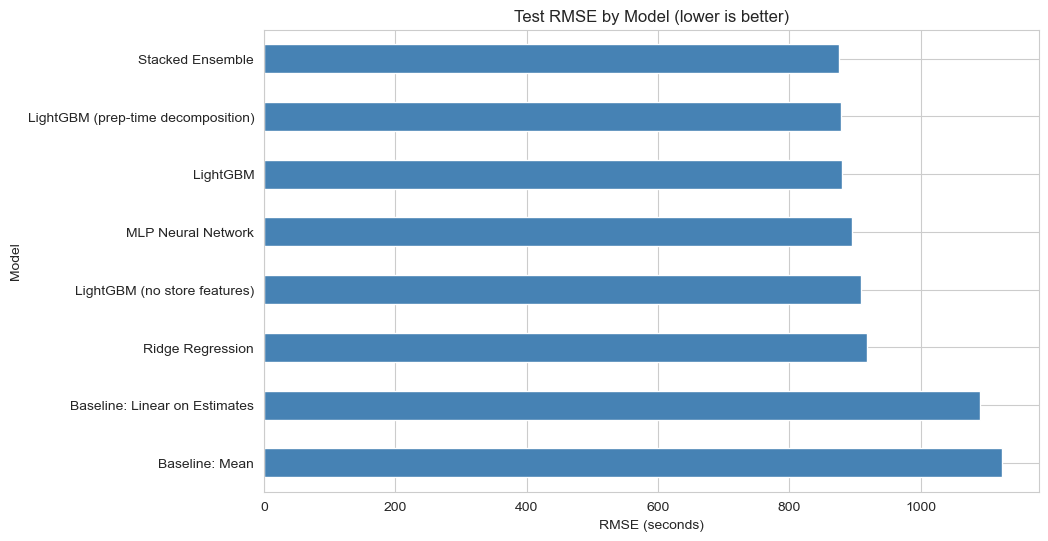

In [132]:
# Plot RMSE of all models
plt.figure(figsize=(10, 6))
results_df['RMSE'].sort_values(ascending=False).plot(kind='barh', color='steelblue')
plt.title('Test RMSE by Model (lower is better)')
plt.xlabel('RMSE (seconds)')
plt.show()

### 5.2 Actual vs Predicted

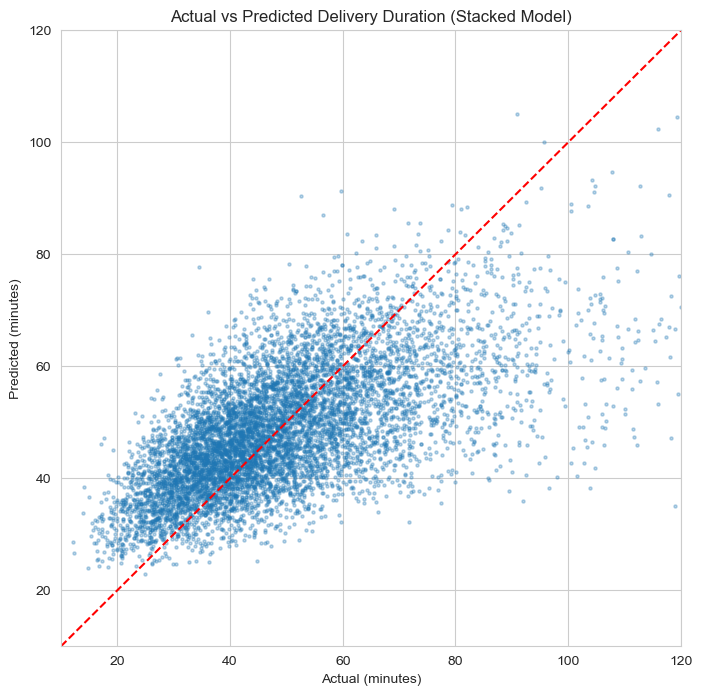

In [133]:
# Actual vs predicted delivery duration for the stacked model
plot_sample = np.random.RandomState(42).choice(len(y_test), 8000, replace=False)

plt.figure(figsize=(8, 8))
plt.scatter(y_test.iloc[plot_sample] / 60, stack_pred[plot_sample] / 60, s=5, alpha=0.3)
plt.plot([10, 120], [10, 120], color='red', linestyle='--')
plt.xlim(10, 120)
plt.ylim(10, 120)
plt.title('Actual vs Predicted Delivery Duration (Stacked Model)')
plt.xlabel('Actual (minutes)')
plt.ylabel('Predicted (minutes)')
plt.show()

- The points follow the red line only loosely. For long deliveries the predictions stay well below the line (under-prediction) and for short deliveries they are above it.

### 5.3 Residual Analysis

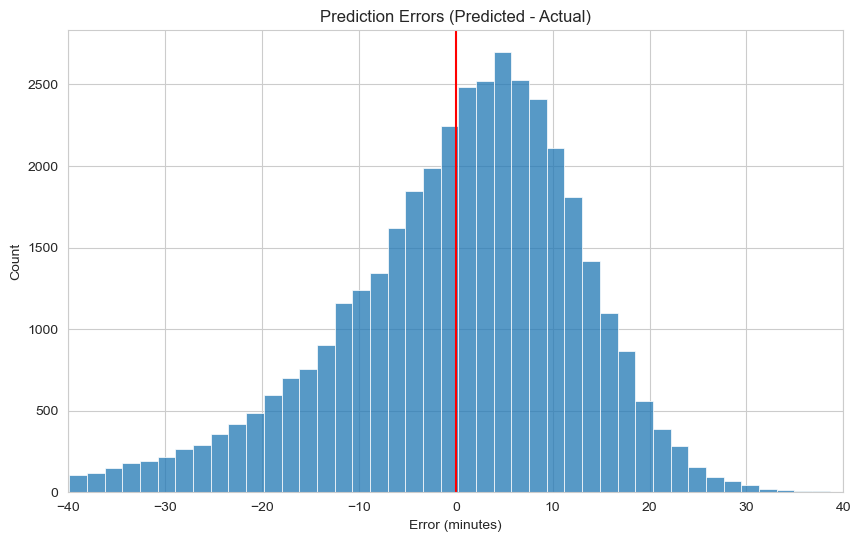

In [134]:
# Prediction errors (predicted - actual) in minutes
test_df['prediction'] = stack_pred
test_df['error'] = test_df['prediction'] - test_df['delivery_duration']

plt.figure(figsize=(10, 6))
sns.histplot(test_df['error'] / 60, bins=100)
plt.axvline(0, color='red')
plt.xlim(-40, 40)
plt.title('Prediction Errors (Predicted - Actual)')
plt.xlabel('Error (minutes)')
plt.show()

- The errors are centered close to zero and fairly wide. The model is not biased overall, but individual orders can be far off.

In [135]:
# Share of orders predicted too early or too late by more than 10 minutes
late = (test_df['error'] < -600).mean() * 100
early = (test_df['error'] > 600).mean() * 100
print(f'Delivered more than 10 min later than predicted: {late:.1f}%')
print(f'Delivered more than 10 min earlier than predicted: {early:.1f}%')

Delivered more than 10 min later than predicted: 20.4%
Delivered more than 10 min earlier than predicted: 20.8%


- About 20% of orders arrive more than 10 minutes later than predicted and about 21% more than 10 minutes earlier. The errors are balanced, so the model is not systematically too optimistic or too pessimistic overall.

### 5.4 Error by Segment

In [136]:
# RMSE and bias by market
def segment_metrics(group):
    return pd.Series({
        'Orders': len(group),
        'RMSE': np.sqrt((group['error'] ** 2).mean()),
        'MAE': group['error'].abs().mean(),
        'Bias': group['error'].mean(),
    })

test_df.groupby('market_id').apply(segment_metrics).round(0)

,Orders,RMSE,MAE,Bias
market_id,,,,
1.0,7359.0,1022.0,747.0,-141.0
2.0,10809.0,770.0,566.0,-39.0
3.0,4685.0,986.0,707.0,-103.0
4.0,9213.0,834.0,600.0,0.0
5.0,3998.0,798.0,585.0,23.0
6.0,3392.0,889.0,649.0,27.0


- Market 1 has the highest error (RMSE about 1,022) and the model under-predicts it by about 2.4 minutes on average. Market 3 is also under-predicted (-97 seconds).
- Market 2 has the lowest error (RMSE about 772). Markets 4, 5 and 6 have almost no bias.
- The under-prediction in markets 1 and 3 may be a sign that conditions changed between the training and test periods.

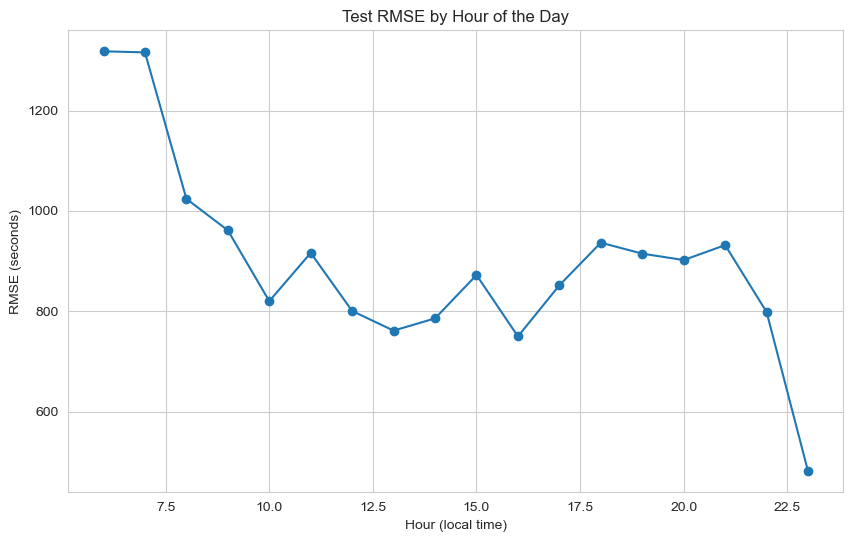

In [137]:
# RMSE by hour of the day
rmse_by_hour = test_df.groupby('hour').apply(lambda g: np.sqrt((g['error'] ** 2).mean()))

plt.figure(figsize=(10, 6))
rmse_by_hour.plot(marker='o')
plt.title('Test RMSE by Hour of the Day')
plt.xlabel('Hour (local time)')
plt.ylabel('RMSE (seconds)')
plt.show()

- The error is largest in the early morning (6 to 7 AM, RMSE about 1,300 seconds), when there are few orders and deliveries are unusually slow.
- During lunch and dinner the RMSE is about 750 to 940 seconds. It is lowest late at night (11 PM, about 565 seconds).

In [138]:
# Error by actual duration group (quintiles)
test_df['duration_group'] = pd.qcut(test_df['delivery_duration'], 5,
                                    labels=['Fastest', 'Fast', 'Medium', 'Slow', 'Slowest'])

test_df.groupby('duration_group').apply(segment_metrics).round(0)

,Orders,RMSE,MAE,Bias
duration_group,,,,
Fastest,7894.0,729.0,628.0,617.0
Fast,7900.0,570.0,447.0,354.0
Medium,7881.0,522.0,409.0,137.0
Slow,7895.0,600.0,486.0,-195.0
Slowest,7887.0,1533.0,1197.0,-1137.0


- The model regresses towards the average. The fastest 20% of deliveries are over-predicted by about 10 minutes and the slowest 20% are under-predicted by about 19 minutes.
- The error is largest for the slowest group (RMSE about 1,528 seconds). The model cannot see the events that cause very long deliveries, such as a slow restaurant or a delayed dasher.

### 5.5 Feature Importance

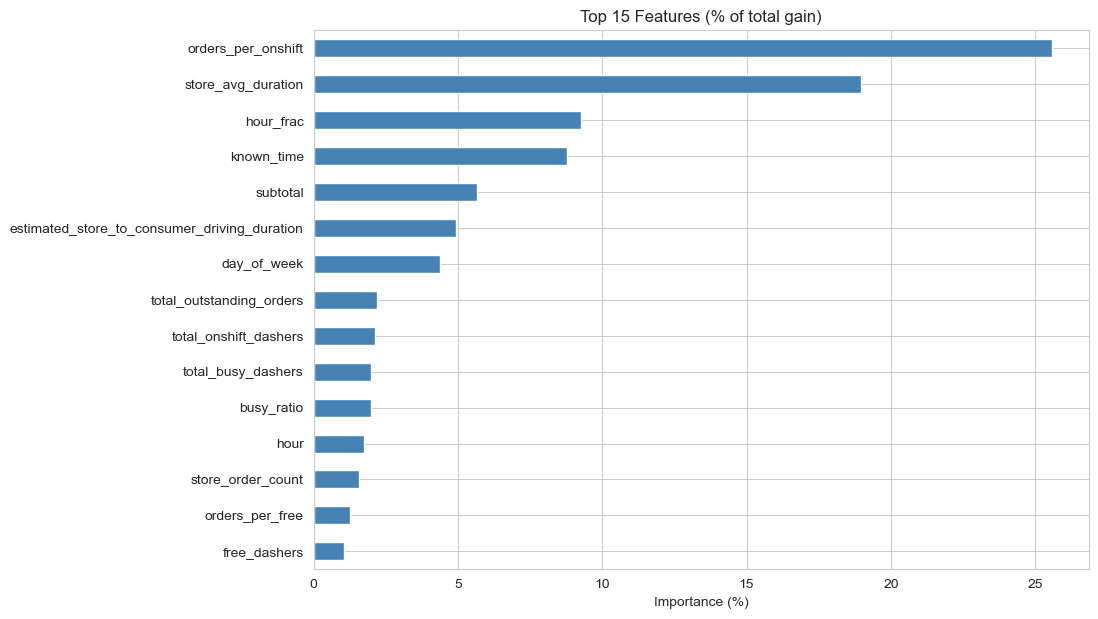

In [139]:
# Top 15 features of the LightGBM model (by gain)
importance = pd.Series(lgbm.feature_importances_, index=feature_cols)
importance = (importance / importance.sum() * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
importance.head(15).sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 15 Features (% of total gain)')
plt.xlabel('Importance (%)')
plt.show()

In [140]:
# Importance values
importance.head(15).round(1)

orders_per_onshift                              25.6
store_avg_duration                              19.0
hour_frac                                        9.3
known_time                                       8.8
subtotal                                         5.6
estimated_store_to_consumer_driving_duration     4.9
day_of_week                                      4.4
total_outstanding_orders                         2.2
total_onshift_dashers                            2.1
total_busy_dashers                               2.0
busy_ratio                                       2.0
hour                                             1.7
store_order_count                                1.6
orders_per_free                                  1.3
free_dashers                                     1.1
dtype: float64

- The most important feature is `orders_per_onshift` (25.6%), followed by the store average duration (19.0%), the time of day (9.3%), the known stage times (8.8%) and the subtotal (5.6%).
- Three of the top four features were engineered in this project. Marketplace load and the store itself explain almost half of the model's predictive power.

## 6. Model Hyperparameter Tuning

The LightGBM model is tuned with a randomized search. A time-series cross-validation is used, so each validation fold is always later in time than its training data.

In [141]:
# Parameter ranges to search
param_grid = {
    'num_leaves': [31, 63, 127],
    'learning_rate': [0.02, 0.03, 0.05],
    'n_estimators': [300, 500, 700],
    'min_child_samples': [20, 50, 100],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [1, 5, 10],
}

search = RandomizedSearchCV(
    LGBMRegressor(subsample=0.8, subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=param_grid, n_iter=8, cv=TimeSeriesSplit(n_splits=3),
    scoring='neg_root_mean_squared_error', random_state=42, n_jobs=-1)

In [142]:
# Run the search (this takes a few minutes)
search.fit(X_train, y_train)

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=LGBMRegressor(random_state=42, subsample=0.8,
                                           subsample_freq=1, verbose=-1),
                   n_iter=8, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.6, 0.8, 1.0],
                                        'learning_rate': [0.02, 0.03, 0.05],
                                        'min_child_samples': [20, 50, 100],
                                        'n_estimators': [300, 500, 700],
                                        'num_leaves': [31, 63, 127],
                                        'reg_lambda': [1, 5, 10]},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [143]:
# Best parameters and cross-validation RMSE
print('Best parameters:', search.best_params_)
print(f'Best CV RMSE: {-search.best_score_:.1f}')

Best parameters: {'reg_lambda': 10, 'num_leaves': 63, 'n_estimators': 300, 'min_child_samples': 100, 'learning_rate': 0.02, 'colsample_bytree': 0.8}
Best CV RMSE: 895.9


- The best parameter set has a cross-validation RMSE of about 896 seconds.

In [144]:
# Evaluate the tuned model on the test set
tuned_pred = search.best_estimator_.predict(X_test)
results.append(utility.evaluate_model('LightGBM (tuned)', y_test, tuned_pred))
pd.DataFrame(results).tail(1)

,Model,RMSE,MAE,R2,Within_10_min_%
8,LightGBM (tuned),882.537115,632.274706,0.373666,59.558507


- The tuned model has an RMSE of about 883 seconds on the test set, slightly worse than the untuned LightGBM (880).
- The default parameters were already close to optimal, so the small search gave no gain.

### 6.1 Final Model Comparison

In [145]:
# Final comparison of all models, sorted by RMSE
pd.DataFrame(results).set_index('Model').round({'RMSE': 1, 'MAE': 1, 'R2': 3, 'Within_10_min_%': 1}).sort_values('RMSE')

,RMSE,MAE,R2,Within_10_min_%
Model,,,,
Stacked Ensemble,876.0,633.5,0.383,58.7
LightGBM (prep-time decomposition),879.0,629.4,0.379,60.1
LightGBM,879.9,630.0,0.377,59.8
LightGBM (tuned),882.5,632.3,0.374,59.6
MLP Neural Network,895.1,651.0,0.356,57.3
LightGBM (no store features),909.2,653.6,0.335,58.0
Ridge Regression,917.6,666.3,0.323,56.3
Baseline: Linear on Estimates,1089.5,806.4,0.045,46.8
Baseline: Mean,1123.7,834.8,-0.015,45.2


- The ranking is: Stacked Ensemble, LightGBM decomposition, LightGBM, tuned LightGBM, MLP, LightGBM without store features, Ridge and then the two baselines.
- All the LightGBM variants and the stack are within about 8 seconds of RMSE of each other.

## 7. Conclusion and Recommendations

### 7.1 Conclusion

The project built and compared several models to predict delivery duration. The research questions are answered below.

1. **How accurately can delivery duration be predicted?** The best model (the stacked ensemble) has an RMSE of about 875 seconds on future orders. This is 22% lower than predicting the average (1,124 seconds) and 20% lower than a linear model on the provided estimates (1,090 seconds). It explains about 38% of the variance (R² 0.384), and about 59 to 60% of the orders are predicted within 10 minutes, compared with 45 to 47% for the baselines.

2. **Which features matter most?** The most important features are marketplace load (orders per on-shift dasher), the average duration of the store, time of day and day of week, and the known stage times. The store features alone improved RMSE by about 29 seconds.

3. **Does the prep-time decomposition help?** Only slightly (RMSE 879.0 compared with 879.9 for the direct model). The idea is sound, but LightGBM can already learn from the estimates when they are given as features.

4. **Does stacking help?** Only a little. The stack has the best RMSE (875.2 compared with 879.0 for the best single model), but its MAE is slightly worse. The gain is small compared with the extra cost of training and serving four models.

**Success criteria:** the technical criterion is met, since the final model clearly beats both baselines on RMSE and the other metrics. The business criterion is also met, since the analysis identifies the main drivers of delivery time.

The models are limited by the information available. Most of the remaining error comes from things that are not in the data, mainly how long the restaurant actually takes to prepare the food.

### 7.2 Recommendations

1. **Use the LightGBM prep-time decomposition model as the main model.** It is almost as accurate as the stacked ensemble (and better on MAE) and much simpler to train, serve and maintain. The stack is only worth using if the extra 4 seconds of RMSE justify the cost.

2. **Add live restaurant prep-time information.** Preparation time is the biggest unknown. Features such as the recent average prep time of each store (calculated only from orders before the current one) should give the largest improvement.

3. **Show a delivery time range, not only a single number.** Models that predict quantiles (for example the 10th and 90th percentiles) can give customers a range. Because late deliveries hurt customers more than early ones, the quoted time can be set slightly on the safe side.

4. **Monitor the model by market and retrain often.** Markets 1 and 3 were under-predicted in the test period. Performance should be tracked by market and hour and the model retrained as new data arrives.

5. **Improve data collection.** Market 6 is missing the dasher information for 95% of its orders and many values contain noise (for example busy dashers above on-shift dashers). Fixing these data issues, and adding distance, weather and traffic information, should help future models.

### 7.3 Limitations and Next Steps

- **Short history:** only about five weeks of data, so seasonality and holidays cannot be learned and store histories are short.
- **Noisy data:** noise was added to the data on purpose, which limits the achievable accuracy.
- **Missing information:** there is no actual preparation time, distance, weather or traffic.
- **Regression to the mean:** the slowest deliveries are under-predicted by about 19 minutes on average, and the fastest are over-predicted by about 10 minutes.
- **Validation:** the stacked model uses standard 5-fold cross-validation to build its out-of-fold predictions. A strictly time-ordered (expanding window) scheme would be more realistic, and a larger hyperparameter search could be run.
- **Neural network:** the MLP is scikit-learn's `MLPRegressor`. A Keras model could be tested as a next step.